## Libraries

In [1]:
# Import needed libraries

import io
import warnings
import contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
from scipy.spatial.distance import jensenshannon
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import grangercausalitytests

# statsmodels turns its own warnings back on when it is imported, so this has to come after the imports.
warnings.filterwarnings('ignore')

## Figure Theme

In [2]:
# Colors and plot style used for every figure so they match the white paper.
NAVY, TAN, ORANGE, TEAL, GREY = '#223343', '#B5A093', '#D9772B', '#3C8D93', '#8A8F94'

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.family': 'serif',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelsize': 10,
})

# Makes the printed tables wide enough to read.
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 30)

## Data Load

In [3]:
# Looks for each data file in this folder, a data folder, the parent folder, or Downloads.
data_folders = [Path('.'), Path('data'), Path('..'), Path('..') / 'data', Path.home() / 'Downloads']
file_names = ['complaints-by-airport.csv', 'complaints-by-category.csv', 'complaints-by-subcategory.csv']

def find_file(file_name):
    for folder in data_folders:
        if (folder / file_name).exists():
            return folder / file_name
    raise FileNotFoundError(f'{file_name} not found. It is in the data folder of this repository. Source: https://github.com/data-liberation-project/tsa-complaint-counts')

airport, category, subcategory = [pd.read_csv(find_file(f), keep_default_na=False) for f in file_names]

for name, df in [('airport', airport), ('category', category), ('subcategory', subcategory)]:
    print(f"{name} file: {len(df):>9,} rows x {df.shape[1]} columns")
print(airport.head())

airport file:    49,045 rows x 4 columns
category file:   291,752 rows x 7 columns
subcategory file:   628,628 rows x 11 columns
  pdf_report_date airport year_month  count
0         2019-02     ABE    2015-01      0
1         2019-02     ABE    2015-02      0
2         2019-02     ABE    2015-03      0
3         2019-02     ABE    2015-04      0
4         2019-02     ABE    2015-05      2


## Data Clean

In [4]:
for df in (airport, category, subcategory):
    # Turns year_month into a real date (the first of each month) so the data can be treated as a time series.
    df['date'] = pd.to_datetime(df['year_month'] + '-01')

    # Some complaints are not tied to any airport and have a blank airport. Instead of dropping them,
    # they are labeled UNATTRIBUTED so nothing is silently removed.
    df['airport'] = df['airport'].replace('', 'UNATTRIBUTED')

print("Blank airports left after labeling:", (airport['airport'] == '').sum())

Blank airports left after labeling: 0


## Data Exploration

In [5]:
# Checks each file for duplicate rows (same airport, category, and month) and negative counts, and compares totals.
# The subcategory file repeats some keys with different counts, so they are separate line items. They are added
# together when needed instead of dropped.
checks = {'Airport': (airport, ['airport', 'date']),
          'Category': (category, ['airport', 'category', 'date']),
          'Subcategory': (subcategory, ['airport', 'category', 'subcategory', 'date'])}
print(pd.DataFrame({name: {'duplicate keys': df.duplicated(keys).sum(),
                           'negative counts': (df['count'] < 0).sum(),
                           'total complaints': f"{df['count'].sum():,}"} for name, (df, keys) in checks.items()}).T)

# All three files describe the same complaints, so every month should add up the same in each file.
monthly_totals = pd.concat([df.groupby('date')['count'].sum() for df, _ in checks.values()], axis=1)
n_months = len(monthly_totals)
print(f"\nMonths in the data: {n_months} ({monthly_totals.index.min():%b %Y} to {monthly_totals.index.max():%b %Y})")
print("Complete month grid:", pd.date_range(monthly_totals.index.min(), monthly_totals.index.max(), freq='MS').equals(monthly_totals.index))
print("Months where the three files disagree:", (monthly_totals.nunique(axis=1) > 1).sum())

            duplicate keys negative counts total complaints
Airport                  0               0        1,366,034
Category                 0               0        1,366,034
Subcategory           7937               0        1,366,034

Months in the data: 129 (Jan 2015 to Sep 2025)
Complete month grid: True
Months where the three files disagree: 0


In [6]:
# Looks at how many complaints have no airport. They are one row per month.
unattributed = airport[airport['airport'] == 'UNATTRIBUTED']
named = airport[airport['airport'] != 'UNATTRIBUTED']
print(f"Unattributed complaints: {unattributed['count'].sum():,} ({unattributed['count'].sum() / airport['count'].sum():.1%} of all complaints)")

# Complaints by year, split into the ones tied to an airport and the ones that are not.
airport['tied_to_airport'] = airport['airport'] != 'UNATTRIBUTED'
yearly = airport.pivot_table(index=airport['date'].dt.year, columns='tied_to_airport', values='count', aggfunc='sum')
yearly.columns = ['Unattributed', 'Attributed to an airport']
yearly['Total'] = yearly.sum(axis=1)
yearly['Attributed share'] = yearly['Attributed to an airport'] / yearly['Total']
print(f"\nComplaints by year (the last year is partial if the data stops before December):")
print(yearly.round(3).to_string(formatters={c: '{:,.0f}'.format for c in ['Unattributed', 'Attributed to an airport', 'Total']}))

# The month with the biggest one-month drop in the share tied to an airport (a change in how the airport field is filled in).
monthly_share = airport.pivot_table(index='date', columns='tied_to_airport', values='count', aggfunc='sum')
monthly_share = monthly_share[True] / monthly_share.sum(axis=1)
share_break = monthly_share.diff().idxmin()
print(f"\nBiggest drop in the share tied to an airport: {share_break - pd.offsets.MonthBegin(1):%b %Y} {monthly_share.shift(1)[share_break]:.1%} -> {share_break:%b %Y} {monthly_share[share_break]:.1%}; average since then {monthly_share[share_break:].mean():.1%}")

# An airport that is missing a month did not report it, which is different from zero complaints.
# Airports missing any month are left out of the airport-level work instead of being filled in.
months_reported = named.groupby('airport')['date'].nunique()
full_coverage = months_reported[months_reported == n_months].index
print(f"\nNamed airports: {len(months_reported)} | reporting all {n_months} months: {len(full_coverage)} | partial coverage: {(months_reported < n_months).sum()}")
print(f"Full-coverage airports hold {named[named['airport'].isin(full_coverage)]['count'].sum() / named['count'].sum():.1%} of named-airport complaints")
print(f"Category labels: {category['category'].nunique()} raw -> {category['clean_cat'].nunique()} after cleaning")

Unattributed complaints: 831,855 (60.9% of all complaints)

Complaints by year (the last year is partial if the data stops before December):
     Unattributed Attributed to an airport   Total  Attributed share
date                                                                
2015       48,933                   44,548  93,481             0.477
2016       59,502                   57,212 116,714             0.490
2017       52,795                   53,757 106,552             0.505
2018       62,771                   52,571 115,342             0.456
2019       63,153                   49,457 112,610             0.439
2020       24,480                   20,846  45,326             0.460
2021       33,147                   47,886  81,033             0.591
2022       71,621                   94,255 165,876             0.568
2023      138,241                   34,536 172,777             0.200
2024      150,443                   43,628 194,071             0.225
2025      126,769              

The three files add up to the same total and the month grid is complete. Per TSA statements reported by FedScoop (2024), the way complaints are collected changed during this period: the contact center moved to Salesforce at the end of 2020 (when the airport field started to populate), a new PreCheck webform launched in May 2021, and messaging changes followed in August 2021. These are marked A and B on Figure 1 and tested in the PreCheck Sensitivity Check at the end. The data also shows a third break that TSA has not explained: in October 2022 the share of complaints tied to an airport falls from about 73% to about 17% and stays near 20%. It is marked C on Figure 1. Earlier releases of the same repository did not show this drop, so it comes from how the newer reports fill in the airport field, not from passengers. The relative-to-nation detector below is built to absorb level shifts like this one.

| Field | Type | Description |
|---|---|---|
| `year_month` / `date` | Text / Date | Month of the complaints (turned into the first of the month) |
| `airport` | Categorical | Airport code (blank means no airport, relabeled UNATTRIBUTED) |
| `clean_cat` | Categorical | Complaint category after the Data Liberation Project's cleaning |
| `count` | Integer | Complaints in that month |

## Data Exploration Visualizations

Lowest month:  Apr 2020 (781)
Highest month: Mar 2025 (21,323)


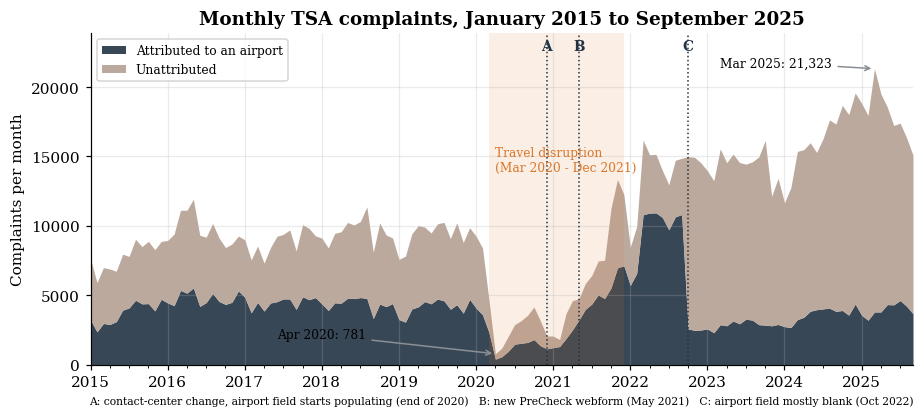

In [7]:
# Monthly complaints, split into the ones tied to an airport and the ones that are not.
monthly = airport.pivot_table(index='date', columns='tied_to_airport', values='count', aggfunc='sum').asfreq('MS')
monthly.columns = ['Unattributed', 'Attributed to an airport']
monthly = monthly[['Attributed to an airport', 'Unattributed']]

# y is the national total for each month. It is used for the forecasting section.
y = monthly.sum(axis=1).astype(float)
low, high = y.idxmin(), y.idxmax()
print(f"Lowest month:  {low:%b %Y} ({y[low]:,.0f})")
print(f"Highest month: {high:%b %Y} ({y[high]:,.0f})")

# Figure 1: monthly complaints with the travel disruption shaded and the two collection changes marked A and B.
top = y.max() * 1.12
fig, ax = plt.subplots(figsize=(8.5, 3.9))
monthly.plot.area(ax=ax, color=[NAVY, TAN], alpha=0.9, linewidth=0)
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-01'), color=ORANGE, alpha=0.12, lw=0)
ax.text(pd.Timestamp('2020-04-15'), top * 0.66, 'Travel disruption\n(Mar 2020 - Dec 2021)', fontsize=8, color=ORANGE, va='top')
ax.annotate(f'{low:%b %Y}: {y[low]:,.0f}', xy=(low, y[low]), xytext=(pd.Timestamp('2017-06-01'), top * 0.08),
            arrowprops=dict(arrowstyle='->', color=GREY), fontsize=8)
ax.annotate(f'{high:%b %Y}: {y[high]:,.0f}', xy=(high, y[high]), xytext=(high - pd.DateOffset(years=2), top * 0.9),
            arrowprops=dict(arrowstyle='->', color=GREY), fontsize=8)
ax.set_ylim(0, top)
for when, tag in [(pd.Timestamp('2020-12-01'), 'A'), (pd.Timestamp('2021-05-01'), 'B'), (share_break, 'C')]:
    ax.axvline(when, color=NAVY, ls=':', lw=1)
    ax.text(when, top * 0.95, tag, ha='center', fontsize=9, fontweight='bold', color=NAVY)
ax.set_title(f'Monthly TSA complaints, {y.index[0]:%B %Y} to {y.index[-1]:%B %Y}')
ax.set_xlabel(f'A: contact-center change, airport field starts populating (end of 2020)   B: new PreCheck webform (May 2021)   C: airport field mostly blank ({share_break:%b %Y})', fontsize=7)
ax.set_ylabel('Complaints per month')
ax.legend(title='', loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

## Forecasting Model Data Prep

In [8]:
# Monthly complaints for each category. This is also used later for the leading indicators and the mix shift.
category_monthly = category.groupby(['date', 'clean_cat'])['count'].sum().unstack(fill_value=0).asfreq('MS')
all_complaints = category_monthly.sum(axis=1)

# PreCheck is the category called Expedited Passenger Screening Program.
precheck = category_monthly['Expedited Passenger Screening Program']

# The same comparison is run on two series: all complaints, and everything except PreCheck.
# The second one is only looked at in the PreCheck Sensitivity Check at the end.
series_to_forecast = {'All complaints': y, 'Without PreCheck': (all_complaints - precheck).astype(float)}

# The last 24 months are the one-month-ahead targets.
targets = y.index[-24:]
print(f"One-month-ahead targets: {targets[0]:%b %Y} to {targets[-1]:%b %Y}")

One-month-ahead targets: Oct 2023 to Sep 2025


## Training & Comparing Models

In [9]:
# Calendar month as a sine and cosine so December sits next to January.
def month_cycle(month):
    return [np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)]

def forecast_all(train, h):
    """Forecasts the next h months with all seven models. Only the training months are used."""
    dates = pd.date_range(train.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq='MS')
    out = pd.DataFrame(index=dates)
    out['Naive (last month)'] = train.iloc[-1]                                  # same as last month
    out['Seasonal naive'] = train.iloc[-12:].values[:h]                         # same month last year
    out['Average of last 12 months'] = train.iloc[-12:].mean()

    # Holt-Winters exponential smoothing with a damped trend and yearly seasonality.
    out['Holt-Winters (damped, seasonal)'] = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit().forecast(h).values

    # SARIMA on the log of the counts. The first differences away the trend and seasonality, the second does not (as a contrast).
    for label, order, seasonal in [('SARIMA (1,1,1)(0,1,1,12)', (1, 1, 1), (0, 1, 1, 12)), ('SARIMA (1,0,0)(1,0,0,12)', (1, 0, 0), (1, 0, 0, 12))]:
        out[label] = np.expm1(SARIMAX(np.log1p(train), order=order, seasonal_order=seasonal).fit(disp=False).forecast(h).values)

    # Random Forest on the last 3 months plus the calendar month. It forecasts one month at a time
    # and feeds each forecast back in as the newest value.
    values, months = list(train.values), train.index.month
    features = [values[i - 3:i] + month_cycle(months[i]) for i in range(3, len(values))]
    forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42).fit(features, values[3:])
    rf = []
    for date in dates:
        rf.append(forest.predict([values[-3:] + month_cycle(date.month)])[0])
        values.append(rf[-1])
    out['Random Forest on lags'] = rf
    return out

# MAE and RMSE are in complaints. MAPE is the average percent miss.
def metrics(actual, forecasts):
    return forecasts.apply(lambda f: pd.Series({'MAE': mean_absolute_error(actual, f),
                                                'RMSE': root_mean_squared_error(actual, f),
                                                'MAPE %': 100 * mean_absolute_percentage_error(actual, f)})).T

one_step_forecasts, results_by_series = {}, {}
for series_name, series in series_to_forecast.items():
    # One month ahead, rolling forward over the last 24 months. Each forecast is trained only on earlier months.
    one_step = pd.concat([forecast_all(series[:t - pd.offsets.MonthBegin(1)], 1) for t in targets])

    # 12-month holdout: train on everything except the last 12 months and forecast those 12.
    twelve = forecast_all(series.iloc[:-12], 12)

    results = pd.concat([metrics(series[targets], one_step).add_prefix('1-step '),
                         metrics(series.iloc[-12:], twelve)[['MAE', 'MAPE %']].add_prefix('12-mo ')], axis=1)
    one_step_forecasts[series_name] = one_step
    results_by_series[series_name] = results.sort_values('1-step MAPE %')

results_all = results_by_series['All complaints']
print(f"Scored on {targets[0]:%b %Y} to {targets[-1]:%b %Y}; average month = {y[targets].mean():,.0f} complaints\n")
print(results_all.round(1))

Scored on Oct 2023 to Sep 2025; average month = 16,585 complaints

                                 1-step MAE  1-step RMSE  1-step MAPE %  12-mo MAE  12-mo MAPE %
Holt-Winters (damped, seasonal)       955.8       1240.9            6.2     1395.9           7.7
Naive (last month)                   1293.0       1579.9            8.2     1431.2           7.7
SARIMA (1,0,0)(1,0,0,12)             1299.0       1588.8            8.2     1545.2           8.2
SARIMA (1,1,1)(0,1,1,12)             1417.3       1684.6            9.1     2184.8          12.2
Random Forest on lags                1553.3       1716.9            9.6     3542.6          18.9
Average of last 12 months            2104.8       2335.8           12.8     3250.3          17.2
Seasonal naive                       2658.3       3312.2           15.4     3837.9          20.6


## Forecasting Visualizations

Best one-step model: Holt-Winters (damped, seasonal) | worst: Seasonal naive


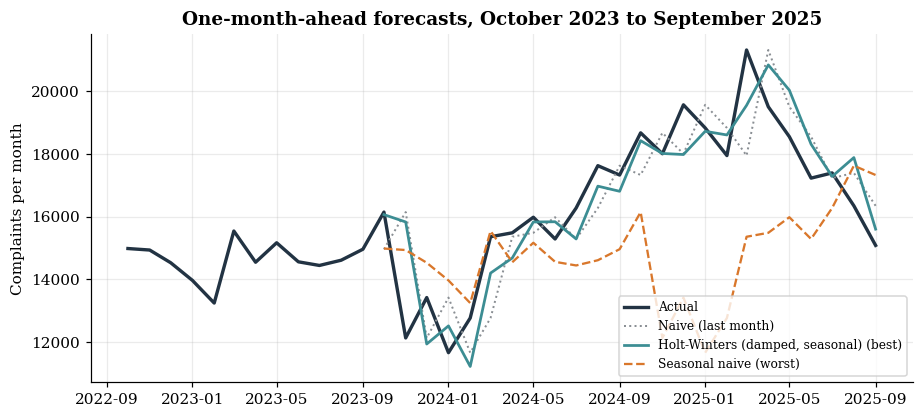

In [10]:
# Picks the best and worst model from the one-month-ahead results to plot against the actual complaints.
best_model, worst_model = results_all.index[0], results_all.index[-1]
print("Best one-step model:", best_model, "| worst:", worst_model)

# Figure 2: one-month-ahead forecasts.
one_step_all = one_step_forecasts['All complaints']
fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.plot(y.index[-36:], y.iloc[-36:], color=NAVY, lw=2.2, label='Actual')
ax.plot(one_step_all.index, one_step_all['Naive (last month)'], color=GREY, lw=1.3, ls=':', label='Naive (last month)')
ax.plot(one_step_all.index, one_step_all[best_model], color=TEAL, lw=1.8, label=f'{best_model} (best)')
ax.plot(one_step_all.index, one_step_all[worst_model], color=ORANGE, lw=1.5, ls='--', label=f'{worst_model} (worst)')
ax.set_title(f'One-month-ahead forecasts, {targets[0]:%B %Y} to {targets[-1]:%B %Y}')
ax.set_ylabel('Complaints per month')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

## Airport-Level Forecasting

In [11]:
# Puts each named airport's monthly complaints in its own column, for the airports that report every month.
airport_wide = named.pivot(index='date', columns='airport', values='count').asfreq('MS')
airport_full = airport_wide[full_coverage]

# Typical monthly complaints at each airport since 2022 (the recovery).
typical = airport_full['2022-01-01':].median()

# The nationwide level across all named airports. This is used for the anomaly detection.
nat_named = airport_wide.sum(axis=1)

# Airports with a typical month of at least 10 complaints are big enough to model.
monitorable = typical[typical >= 10].index

# For each of those airports, forecast the last 12 months with four simple models and save the error.
rows = []
for ap in monitorable:
    train, actual = airport_full[ap].iloc[:-12], airport_full[ap].iloc[-12:].values

    # Holt-Winters needs positive numbers to be stable, so 1 is added and then taken back off.
    # If it fails for a tiny airport, the last 6 months' average is used instead.
    try:
        hw_pred = np.clip(ExponentialSmoothing(train + 1, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit().forecast(12).values - 1, 0, None)
    except Exception:
        hw_pred = np.repeat(train.iloc[-6:].mean(), 12)

    predictions = {'Naive (last month)': np.repeat(train.iloc[-1], 12),
                   'Seasonal naive': train.iloc[-12:].values,
                   'Average of last 12 months': np.repeat(train.iloc[-12:].mean(), 12),
                   'Holt-Winters (damped, seasonal)': hw_pred}
    rows += [(ap, model, np.abs(actual - pred).sum(), actual.sum()) for model, pred in predictions.items()]

airport_results = pd.DataFrame(rows, columns=['airport', 'model', 'abs_err', 'actual'])

# Pooled WAPE adds up all the errors first. The median is the typical single airport.
summary = airport_results.groupby('model').agg(abs_err=('abs_err', 'sum'), actual=('actual', 'sum'))
summary['Pooled WAPE %'] = 100 * summary['abs_err'] / summary['actual']
airport_results['wape'] = 100 * airport_results['abs_err'] / airport_results['actual'].replace(0, np.nan)
summary['Median airport WAPE %'] = airport_results.groupby('model')['wape'].median()

print(f"Airports modeled: {len(monitorable)} (typical monthly complaints >= 10 since 2022), 12-month holdout")
print(summary[['Pooled WAPE %', 'Median airport WAPE %']].sort_values('Pooled WAPE %').round(1))

# How does forecast error change with airport size? Uses the 12-month average model on every full-coverage airport.
tier = pd.cut(typical, [0, 5, 20, 100, np.inf], labels=['Under 5', '5 to 19', '20 to 99', '100 or more'], right=False, include_lowest=True)
tier_errors = pd.DataFrame({'tier': tier,
                            'abs_err': [np.abs(airport_full[ap].iloc[-12:].values - airport_full[ap].iloc[:-12].iloc[-12:].mean()).sum() for ap in airport_full.columns],
                            'actual': airport_full.iloc[-12:].sum().values})
by_tier = tier_errors.groupby('tier', observed=True).agg(airports=('tier', 'size'), abs_err=('abs_err', 'sum'), actual=('actual', 'sum'))
by_tier['WAPE %'] = 100 * by_tier['abs_err'] / by_tier['actual']
print(f"\nTypical monthly complaints per airport ({len(airport_full.columns)} full-coverage airports), then forecast error:")
print(by_tier[['airports', 'WAPE %']].round(1))

Airports modeled: 69 (typical monthly complaints >= 10 since 2022), 12-month holdout
                                 Pooled WAPE %  Median airport WAPE %
model                                                                
Holt-Winters (damped, seasonal)           21.5                   23.9
Average of last 12 months                 22.8                   25.4
Naive (last month)                        23.9                   25.8
Seasonal naive                            26.1                   30.8

Typical monthly complaints per airport (223 full-coverage airports), then forecast error:
             airports  WAPE %
tier                         
Under 5           123    65.2
5 to 19            58    34.4
20 to 99           31    23.3
100 or more        11    20.3


## Leading Indicators

In [12]:
# The ten biggest categories by total complaints.
top_cats = category_monthly.sum().sort_values(ascending=False).head(10).index

rows = []
for cat in top_cats:
    # Month-over-month change in the log of this category, and of everything except this category.
    changes = pd.concat([np.log1p(all_complaints - category_monthly[cat]).diff(), np.log1p(category_monthly[cat]).diff()], axis=1).dropna()
    changes.columns = ['others', 'own']

    # Does this category help predict the rest? And does the rest help predict this category?
    # (The test prints a long report for every lag, so the printing is turned off.)
    with contextlib.redirect_stdout(io.StringIO()):
        forward = grangercausalitytests(changes[['others', 'own']], maxlag=3)
        reverse = grangercausalitytests(changes[['own', 'others']], maxlag=3)

    # Keeps the lag (1, 2, or 3 months) with the smallest p-value.
    forward_p = {lag: forward[lag][0]['ssr_ftest'][1] for lag in (1, 2, 3)}
    best_lag = min(forward_p, key=forward_p.get)
    rows.append((cat, best_lag, forward_p[best_lag], min(reverse[lag][0]['ssr_ftest'][1] for lag in (1, 2, 3))))

granger = pd.DataFrame(rows, columns=['Category', 'Best lag (months)', 'p: category leads', 'p: rest leads category'])
granger['p after Bonferroni'] = (granger['p: category leads'] * len(granger)).clip(upper=1)
granger['Passes (p < 0.05)'] = granger['p after Bonferroni'] < 0.05
print(granger.round(4))

                                Category  Best lag (months)  p: category leads  p: rest leads category  p after Bonferroni  Passes (p < 0.05)
0  Expedited Passenger Screening Program                  1             0.0032                  0.1671              0.0321               True
1      Mishandling of Passenger Property                  1             0.0011                  0.0080              0.0106               True
2                       Customer Service                  3             0.0210                  0.1486              0.2100              False
3                              Screening                  1             0.9174                  0.0636              1.0000              False
4            Property - Special Handling                  2             0.5305                  0.2077              1.0000              False
5          Persons w/ Disabilities (PWD)                  2             0.4530                  0.0465              1.0000              False
6     

## Leading Indicators Visualizations

                                 Same month  1 mo earlier  2 mo earlier  3 mo earlier
Expedited Passenger Screenin...        0.78          0.16         -0.04         -0.19
Mishandling of Passenger Pro...        0.68         -0.14         -0.16         -0.04
Customer Service                       0.71         -0.01         -0.17          0.03
Screening                              0.74          0.07         -0.11         -0.12
Property - Special Handling            0.19          0.07          0.06         -0.08
Persons w/ Disabilities (PWD)          0.86          0.07         -0.16         -0.10
Locks                                  0.73          0.07         -0.06         -0.21
No Jurisdiction                        0.62         -0.04         -0.06         -0.18
Patdown                                0.71          0.16         -0.14         -0.08
Civil Rights                           0.56          0.09         -0.07         -0.03


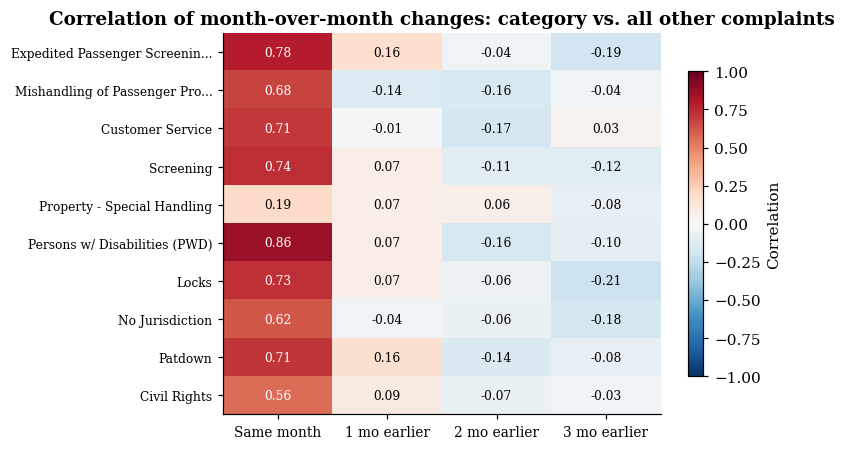

In [13]:
# For each category, how closely does its change k months earlier line up with the change in everything else this month?
lag_corr = pd.DataFrame(
    [[np.log1p(category_monthly[cat]).diff().shift(lag).corr(np.log1p(all_complaints - category_monthly[cat]).diff()) for lag in range(4)] for cat in top_cats],
    index=[c if len(c) < 30 else c[:28] + '...' for c in top_cats],
    columns=['Same month', '1 mo earlier', '2 mo earlier', '3 mo earlier'])
print(lag_corr.round(2))

# Figure 3: heatmap of those correlations.
fig, ax = plt.subplots(figsize=(7.2, 4.2))
im = ax.imshow(lag_corr.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(4))
ax.set_xticklabels(lag_corr.columns, fontsize=9)
ax.set_yticks(range(len(lag_corr)))
ax.set_yticklabels(lag_corr.index, fontsize=8)
for i in range(lag_corr.shape[0]):
    for j in range(lag_corr.shape[1]):
        ax.text(j, i, f'{lag_corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(lag_corr.values[i, j]) > 0.5 else 'black')
ax.grid(False)
ax.set_title('Correlation of month-over-month changes: category vs. all other complaints')
fig.colorbar(im, ax=ax, shrink=0.8, label='Correlation')
plt.tight_layout()
plt.show()

## Anomaly Detection

In [14]:
# Settings for the detector.
window = 12        # months of history used for each airport's baseline
floor = 0.15       # smallest allowed MAD, so tiny airports do not flag on one extra complaint
min_count = 10     # smallest count that can be flagged
cutoff = 3.5       # score needed to flag a month

# The airports that are big enough to model. The relative version subtracts the log of the nationwide level.
M = airport_full[monitorable]
log_own = np.log1p(M)
log_relative = np.log1p(M).sub(np.log1p(nat_named), axis=0)

# Median and MAD of each airport's PREVIOUS 12 months, month by month, so the detector could run live.
# 1.4826 makes the MAD comparable to a standard deviation.
def baseline(log_counts):
    median = pd.DataFrame(np.nan, index=M.index, columns=M.columns)
    mad = median.copy()
    for i in range(window, len(M)):
        past = log_counts.iloc[i - window:i]
        median.iloc[i] = past.median().values
        mad.iloc[i] = ((past - past.median()).abs().median() * 1.4826).values
    return median, mad

median_own, mad_own = baseline(log_own)
median_relative, mad_relative = baseline(log_relative)

# The score is how many MADs above the baseline the month is.
z_own = (log_own - median_own) / mad_own.clip(lower=floor)
z_relative = (log_relative - median_relative) / mad_relative.clip(lower=floor)

# Each airport's typical level (median of the previous 12 months of raw counts).
prior_median = M.shift(1).rolling(window).median()

# A month is flagged if the score is high, there are enough complaints, and the count is above the typical level.
def flagged(z, counts, base, threshold=cutoff):
    return (z > threshold) & (counts >= min_count) & (counts > base)

flags_own, flags_relative = flagged(z_own, M, prior_median), flagged(z_relative, M, prior_median)

# Flags per 100 airport-years, and how many fall in the 2021-2022 rebound.
months_scored = z_own.notna().sum().sum()
per_100 = lambda flags: 100 * flags.sum().sum() / (months_scored / 12)
rebound = slice('2021-03-01', '2022-06-01')
print(f"Airport-months evaluated: {months_scored:,} ({len(M.columns)} airports)")
for label, flags in [('Own history           ', flags_own), ('Relative to the nation', flags_relative)]:
    print(f"{label} flags: {flags.sum().sum():>3}  ({per_100(flags):.1f} per 100 airport-years) | flags during the Mar 2021 - Jun 2022 rebound: {flags.loc[rebound].sum().sum()}")

Airport-months evaluated: 8,073 (69 airports)
Own history            flags:  84  (12.5 per 100 airport-years) | flags during the Mar 2021 - Jun 2022 rebound: 60
Relative to the nation flags:  25  (3.7 per 100 airport-years) | flags during the Mar 2021 - Jun 2022 rebound: 5


In [15]:
# Validation: picks 400 real airport-months (June 2022 to the month before the last) at random.
# The same 400 are used for every spike size and for both detectors so the comparison is fair.
rng = np.random.default_rng(42)
cells = [(ap, month) for ap in M.columns for month in M.loc['2022-06-01':M.index[-2]].index]
sample = [cells[i] for i in rng.choice(len(cells), 400, replace=False)]

# Each month gets a fake spike that is 1.5, 2, 3, or 5 times the airport's typical level.
spike_multiples = [1.5, 2, 3, 5]
trials = []
for ap, month in sample:
    typical_level, original_count = prior_median.loc[month, ap], M.loc[month, ap]
    for multiple in spike_multiples:
        new_count = int(round(typical_level * multiple))

        # The baseline only uses earlier months, so it does not change. The nationwide total goes up by the extra complaints.
        new_nation = nat_named.loc[month] + new_count - original_count
        trials.append({'multiple': multiple, 'count': new_count, 'base': typical_level,
                       'z_own': (np.log1p(new_count) - median_own.loc[month, ap]) / max(mad_own.loc[month, ap], floor),
                       'z_relative': (np.log1p(new_count) - np.log1p(new_nation) - median_relative.loc[month, ap]) / max(mad_relative.loc[month, ap], floor)})
trials = pd.DataFrame(trials)

# Share of the fake spikes each detector catches at the cutoff.
def caught(t, column, threshold=cutoff):
    return flagged(t[column], t['count'], t['base'], threshold).mean()

recall_table = pd.DataFrame([(caught(trials[trials['multiple'] == m], 'z_own'), caught(trials[trials['multiple'] == m], 'z_relative')) for m in spike_multiples],
                            index=[f'{m}x typical' for m in spike_multiples], columns=['Own history', 'Relative to the nation'])
print(f"Share of injected spikes caught at threshold {cutoff} (n = {len(sample)} airport-months per spike size):")
print((100 * recall_table).round(1))

# What happens if the cutoff is changed? Looks at the 3x spikes and at how often each detector flags real months.
t3 = trials[trials['multiple'] == 3]
sensitivity = pd.DataFrame([(th, 100 * caught(t3, 'z_own', th), 100 * caught(t3, 'z_relative', th),
                             per_100(flagged(z_own, M, prior_median, th)), per_100(flagged(z_relative, M, prior_median, th)))
                            for th in [2.5, 3.0, 3.5, 4.0]],
                           columns=['threshold', 'recall, own history %', 'recall, relative %',
                                    'flags per 100 airport-years, own', 'flags per 100 airport-years, relative']).set_index('threshold')
print("\nSensitivity to the threshold (3x spikes):")
print(sensitivity.round(1))

Share of injected spikes caught at threshold 3.5 (n = 400 airport-months per spike size):
              Own history  Relative to the nation
1.5x typical          0.0                    19.8
2x typical           18.5                    39.0
3x typical           51.0                    73.2
5x typical           78.2                    92.2

Sensitivity to the threshold (3x spikes):
           recall, own history %  recall, relative %  flags per 100 airport-years, own  flags per 100 airport-years, relative
threshold                                                                                                                    
2.5                         75.2                88.5                              44.6                                   17.4
3.0                         60.0                80.2                              23.2                                    7.6
3.5                         51.0                73.2                              12.5                           

## Anomaly Detection Visualizations

Example: EWR, Mar 2022: 664 complaints vs a typical 171.5


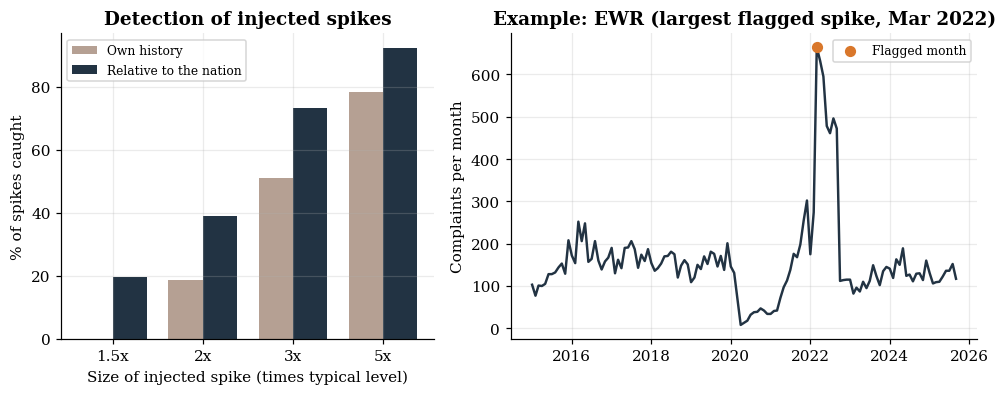

In [16]:
# The example airport is the flagged month with the biggest jump over the airport's typical level.
excess = (M - prior_median).where(flags_relative).stack()
example_month, example_airport = excess.idxmax()
flag_dates = M.index[flags_relative[example_airport].values]
print(f"Example: {example_airport}, {example_month:%b %Y}: {M.loc[example_month, example_airport]:.0f} complaints vs a typical {prior_median.loc[example_month, example_airport]:.1f}")

# Figure 4: left, how many fake spikes each detector catches. Right, the example airport with its flagged months.
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.7), gridspec_kw={'width_ratios': [1, 1.25]})
x, bar_width = np.arange(len(spike_multiples)), 0.38
axes[0].bar(x - bar_width / 2, 100 * recall_table['Own history'], bar_width, color=TAN, label='Own history')
axes[0].bar(x + bar_width / 2, 100 * recall_table['Relative to the nation'], bar_width, color=NAVY, label='Relative to the nation')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'{m}x' for m in spike_multiples])
axes[0].set_xlabel('Size of injected spike (times typical level)')
axes[0].set_ylabel('% of spikes caught')
axes[0].set_title('Detection of injected spikes')
axes[0].legend(fontsize=8)

axes[1].plot(M.index, M[example_airport].values, color=NAVY, lw=1.6)
axes[1].scatter(flag_dates, M.loc[flag_dates, example_airport], color=ORANGE, zorder=3, s=40, label='Flagged month')
axes[1].set_title(f'Example: {example_airport} (largest flagged spike, {example_month:%b %Y})')
axes[1].set_ylabel('Complaints per month')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Category Mix Shift

In [17]:
# Labels every month as Pre, Disruption, or Recovery.
last_month = category_monthly.index[-1]
pre_mask = category_monthly.index < '2020-03-01'
period_names = np.where(pre_mask, '1 Pre (Jan 2015 - Feb 2020)',
                        np.where(category_monthly.index < '2022-01-01', '2 Disruption (Mar 2020 - Dec 2021)', f'3 Recovery (Jan 2022 - {last_month:%b %Y})'))

# Each category's share of the complaints in each period.
mix = category_monthly.groupby(period_names).sum().T
share = mix / mix.sum()
share.columns = [c[2:] for c in share.columns]
share['Change, recovery vs pre (pts)'] = 100 * (share.iloc[:, 2] - share.iloc[:, 0])

# The eight biggest categories.
top8 = category_monthly.sum().sort_values(ascending=False).head(8).index
table = share.loc[top8].copy()
table.iloc[:, :3] = 100 * table.iloc[:, :3]
print("Share of complaints by period (%), eight largest categories:")
print(table.round(1))
print("\nComplaints per month by period:", category_monthly.groupby(period_names).sum().sum(axis=1).div(pd.Series(period_names).value_counts().sort_index().values).round(0).to_dict())

Share of complaints by period (%), eight largest categories:
                                       Pre (Jan 2015 - Feb 2020)  Disruption (Mar 2020 - Dec 2021)  Recovery (Jan 2022 - Sep 2025)  Change, recovery vs pre (pts)
clean_cat                                                                                                                                                        
Expedited Passenger Screening Program                       40.4                              59.6                            76.6                           36.3
Mishandling of Passenger Property                           20.7                               5.2                             1.9                          -18.9
Customer Service                                             8.9                               9.5                             6.2                           -2.7
Screening                                                    7.2                               6.5                             5.

In [18]:
# Distance of each month's category mix from the pre-2020 mix (shares that add up to 1).
def mix_distance(counts):
    pre_mix = counts[pre_mask].sum() / counts[pre_mask].sum().sum()
    return pd.Series([jensenshannon(counts.loc[m] / counts.loc[m].sum(), pre_mix, base=2) for m in counts.index], index=counts.index)

jsd = mix_distance(category_monthly)

# The normal range is the 95th percentile of the distances before 2020.
band = jsd[pre_mask].quantile(0.95)
recovery = jsd['2022-01-01':]
print(f"Pre-2020 month-to-month wobble (95th percentile of distance): {band:.3f}")
print(f"Recovery months: average distance {recovery.mean():.3f}; {(recovery > band).mean():.0%} of months sit outside the pre-2020 band")
print(f"Disruption months: average distance {jsd['2020-03-01':'2021-12-01'].mean():.3f}")

Pre-2020 month-to-month wobble (95th percentile of distance): 0.250
Recovery months: average distance 0.389; 100% of months sit outside the pre-2020 band
Disruption months: average distance 0.272


## Category Mix Shift Visualizations

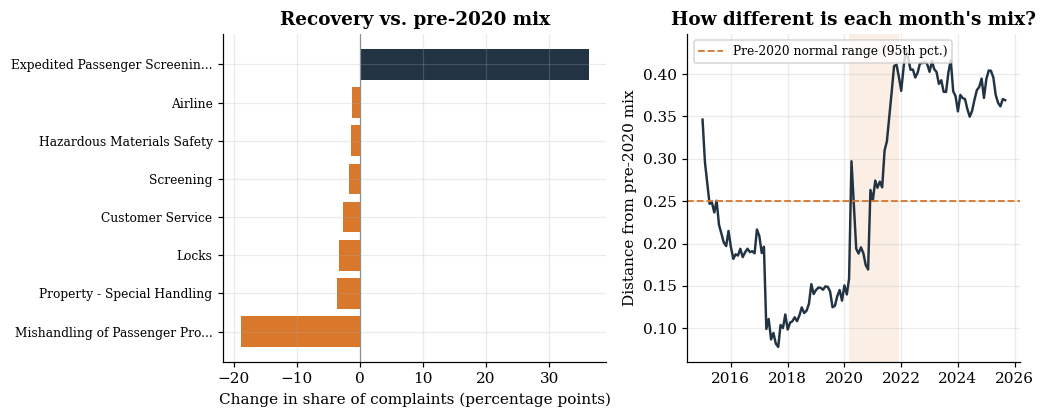

In [19]:
# Categories whose share changed by at least one point.
change = share['Change, recovery vs pre (pts)'].dropna()
change = change[change.abs() >= 1].sort_values()
change_names = [c if len(c) < 30 else c[:28] + '...' for c in change.index]

# Figure 5: left, how the mix changed. Right, how far each month is from the pre-2020 mix.
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), gridspec_kw={'width_ratios': [1.15, 1]})
axes[0].barh(change_names, change.values, color=[ORANGE if v < 0 else NAVY for v in change.values])
axes[0].axvline(0, color=GREY, lw=0.8)
axes[0].set_xlabel('Change in share of complaints (percentage points)')
axes[0].set_title('Recovery vs. pre-2020 mix')
axes[0].tick_params(axis='y', labelsize=8)

axes[1].plot(jsd.index, jsd.values, color=NAVY, lw=1.6)
axes[1].axhline(band, color=ORANGE, ls='--', lw=1.2, label='Pre-2020 normal range (95th pct.)')
axes[1].axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-01'), color=ORANGE, alpha=0.12, lw=0)
axes[1].set_ylabel('Distance from pre-2020 mix')
axes[1].set_title("How different is each month's mix?")
axes[1].legend(fontsize=8, loc='upper left')
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

## PreCheck Sensitivity Check

In [20]:
# Complaints by year with PreCheck split out. Only complete years are shown.
yearly_compare = pd.DataFrame({'All complaints': all_complaints.resample('YS').sum(), 'PreCheck': precheck.resample('YS').sum()})
yearly_compare['Everything else'] = yearly_compare['All complaints'] - yearly_compare['PreCheck']
yearly_compare.index = yearly_compare.index.year
last_full = last_month.year if last_month.month == 12 else last_month.year - 1
print(yearly_compare.loc[:last_full].astype(int).to_string(formatters={c: '{:,}'.format for c in yearly_compare.columns}))
for column in ['Everything else', 'PreCheck']:
    print(f"{column}, {last_full} vs 2019: {yearly_compare.loc[last_full, column] / yearly_compare.loc[2019, column] - 1:+.0%}")

# The forecast comparison from earlier, run on everything except PreCheck.
results_ex = results_by_series['Without PreCheck']
print(f"\nWithout PreCheck: average month = {series_to_forecast['Without PreCheck'][targets].mean():,.0f} complaints")
print(results_ex[['1-step MAPE %', '12-mo MAPE %']].round(1))

# The mix distance from earlier, run on everything except PreCheck.
jsd_ex = mix_distance(category_monthly.drop(columns='Expedited Passenger Screening Program'))
band_ex, recovery_ex = jsd_ex[pre_mask].quantile(0.95), jsd_ex['2022-01-01':]
print(f"\nWithout PreCheck: pre-2020 normal range {band_ex:.3f}; recovery months average {recovery_ex.mean():.3f}; {(recovery_ex > band_ex).mean():.0%} of recovery months sit outside the range")

     All complaints PreCheck Everything else
date                                        
2015         93,481   33,597          59,884
2016        116,714   46,810          69,904
2017        106,552   40,002          66,550
2018        115,342   49,694          65,648
2019        112,610   49,173          63,437
2020         45,326   17,832          27,494
2021         81,033   54,672          26,361
2022        165,876  134,190          31,686
2023        172,777  135,471          37,306
2024        194,071  144,266          49,805
Everything else, 2024 vs 2019: -21%
PreCheck, 2024 vs 2019: +193%

Without PreCheck: average month = 4,283 complaints
                                 1-step MAPE %  12-mo MAPE %
Holt-Winters (damped, seasonal)            5.3           7.9
SARIMA (1,1,1)(0,1,1,12)                   6.5          10.3
SARIMA (1,0,0)(1,0,0,12)                   7.4          11.8
Naive (last month)                         7.7          11.1
Random Forest on lags                

## Summary of Results

In [21]:
print("RQ1 forecasting")
print(f"  Best one-month-ahead model: {results_all.index[0]} (MAPE {results_all.iloc[0]['1-step MAPE %']:.1f}%); naive = {results_all.loc['Naive (last month)', '1-step MAPE %']:.1f}%; worst = {results_all.index[-1]} ({results_all.iloc[-1]['1-step MAPE %']:.1f}%)")
print(f"  Airport level (>=10 complaints/month): best pooled WAPE {summary['Pooled WAPE %'].min():.1f}% ({summary['Pooled WAPE %'].idxmin()})")
print("RQ2 leading indicators")
print(f"  Categories passing the corrected Granger test: {granger.loc[granger['Passes (p < 0.05)'], 'Category'].tolist()}")
print(f"  Average same-month correlation: {lag_corr['Same month'].mean():.2f} | average at 1-3 month lags: {lag_corr.iloc[:, 1:].abs().mean().mean():.2f}")
print("RQ3 anomaly detection")
print(f"  Spikes of 3x caught: own history {100 * recall_table.loc['3x typical', 'Own history']:.0f}% vs relative-to-nation {100 * recall_table.loc['3x typical', 'Relative to the nation']:.0f}%")
print("RQ4 mix shift")
print(f"  Recovery months outside the pre-2020 normal range: {(recovery > band).mean():.0%} (without PreCheck: {(recovery_ex > band_ex).mean():.0%})")
print("Sensitivity (PreCheck set aside)")
print(f"  Best one-month-ahead model: {results_ex.index[0]} (MAPE {results_ex.iloc[0]['1-step MAPE %']:.1f}%); naive = {results_ex.loc['Naive (last month)', '1-step MAPE %']:.1f}%")

RQ1 forecasting
  Best one-month-ahead model: Holt-Winters (damped, seasonal) (MAPE 6.2%); naive = 8.2%; worst = Seasonal naive (15.4%)
  Airport level (>=10 complaints/month): best pooled WAPE 21.5% (Holt-Winters (damped, seasonal))
RQ2 leading indicators
  Categories passing the corrected Granger test: ['Expedited Passenger Screening Program', 'Mishandling of Passenger Property']
  Average same-month correlation: 0.66 | average at 1-3 month lags: 0.10
RQ3 anomaly detection
  Spikes of 3x caught: own history 51% vs relative-to-nation 73%
RQ4 mix shift
  Recovery months outside the pre-2020 normal range: 100% (without PreCheck: 100%)
Sensitivity (PreCheck set aside)
  Best one-month-ahead model: Holt-Winters (damped, seasonal) (MAPE 5.3%); naive = 7.7%
